# 02 — Components, parameters and filters

A simulation is four components: a `Telescope`, a `Sensor`, a `Scene` (star, planet, zodi,
exozodi) and a `Coronagraph`. `from_default` assembles them from the bundled configuration;
you can also build them yourself, and change any parameter afterwards with `update()`.

In this notebook:
1. the four components and `from_components`,
2. `update()` and `reset()`,
3. magnitudes: which band, which system,
4. the twelve filters, end of life and beginning of life,
5. the photometric aperture.

In [1]:
import warnings
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()
warnings.filterwarnings("ignore", module="synphot")

from esc_etc import Telescope, Sensor, Coronagraph, get_scene, FILTERS

***
## 1. The four components

In [2]:
tel = Telescope.from_default(filter="R3")
sen = Sensor.from_default(tel, filter="R3", lifetime="eol")
scene = get_scene(tel, hoststarmag=4.83, hoststar_band="johnson_v", planetdeltamag=20, bg_flux=22.5, exobg_flux=21)
cor = Coronagraph.from_default(tel, raw_dh_contrast=1e-8, ppgain=10, separation=0.4)

print(f"telescope: D = {tel.diameter_primary}, secondary {tel.diameter_secondary}, collecting area {tel.surface:.2f}, "
      f"f/{tel.f_num:.1f}, jitter {tel.jitter_rms.to(u.mas):.0f}, central wavelength {tel.primary_filter.to(u.nm):.0f}")
print(f"sensor:    {sen.pixel_size} pixels at {sen.plate_scale * 1e3:.2f} mas/px, read noise {sen.read_noise:.2f}, "
      f"dark {sen.dark_current:.4f}, well {sen.well_depth:.0f}")
print(f"scene:     star V = {scene.star.mag} ({scene.star.mag_system}), planet {scene.planet.deltamag} mag fainter, "
      f"zodi {scene.zodi.mag} mag/arcsec² in V, exozodi {scene.exozodi.mag:.2f} mag/arcsec² in the ESC band")
print(f"coronagraph: raw contrast {cor.raw_dh_contrast}, ppgain {cor.ppgain}, separation {cor.separation} arcsec")

sim = Simulation.from_components(tel, sen, scene, cor)
same = Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band="johnson_v", planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)
print(f"\nS/N in 1 h: {sim.get_snr(3600, 100)['snr']:.3f} from components, {same.get_snr(3600, 100)['snr']:.3f} from_default")

telescope: D = 3.0 m, secondary 0.22 m, collecting area 5.73 m2, f/36.7, jitter 10 mas, central wavelength 659 nm
sensor:    4.63 um / pix pixels at 8.67 mas/px, read noise 1.83 electron(1/2) / pix(1/2), dark 0.0027 electron / (pix s), well 15261 electron / pix
scene:     star V = 4.83 (vega), planet 20 mag fainter, zodi 22.5 mag/arcsec² in V, exozodi 25.83 mag/arcsec² in the ESC band
coronagraph: raw contrast 1e-08, ppgain 10, separation 0.4 arcsec



S/N in 1 h: 4.587 from components, 4.587 from_default


***
## 2. `update()` and `reset()`

Any parameter is reachable as `component__parameter` (two underscores; a nested element adds a
level, `scene__star__mag`). `update` recomputes what depends on it; `reset` restores the state the
simulation was built with. Invalid values are refused.

In [3]:
base = sim.get_snr(3600, 100)["snr"]
sim.update(scene__star__mag=6.0)
print(f"host 1.2 mag fainter:      S/N = {sim.get_snr(3600, 100)['snr']:.3f}")
sim.update(coronagraph__ppgain=100)
print(f"... and ppgain 100:        S/N = {sim.get_snr(3600, 100)['snr']:.3f}")
sim.update(coronagraph__separation=0.15)
print(f"... and 0.15 arcsec:       S/N = {sim.get_snr(3600, 100)['snr']:.3f}")
try:
    sim.update(sensor__encircled_energy=1.7)
except ValueError as err:
    print("refused:", err)
sim.reset()
print(f"after reset:               S/N = {sim.get_snr(3600, 100)['snr']:.3f} (was {base:.3f})")

host 1.2 mag fainter:      S/N = 1.838


... and ppgain 100:        S/N = 1.869
... and 0.15 arcsec:       S/N = 1.009
refused: encircled_energy must be in (0, 1], got 1.7


after reset:               S/N = 4.587 (was 4.587)


***
## 3. Magnitudes

`hoststarmag` is quoted in `hoststar_band`: `"johnson_v"` for a catalogue V magnitude, or `None`
for the ESC filter itself. `planetdeltamag` is the planet's faintness relative to the host in the
ESC band (contrast $C = 10^{-0.4\,\Delta m}$). `mag_system` is `"vega"` (default) or `"AB"`.
The spectra behind these are **flat**: the ETC has no colour terms, so a red M dwarf quoted in V is
treated as if it were as bright in R3 as in V.

In [4]:
for band, label in ((None, "ESC band (R3)"), ("johnson_v", "Johnson V")):
    s = Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band=band, planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)
    print(f"host 4.83 in {label:14s}: S/N in 1 h = {s.get_snr(3600, 100)['snr']:.3f}")
s = Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band="johnson_v", mag_system="AB", planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)
print(f"host 4.83 in Johnson V, AB   : S/N in 1 h = {s.get_snr(3600, 100)['snr']:.3f}")
for dm in (17.5, 20, 22.5):
    sim.update(scene__planet__deltamag=dm)
    print(f"planet delta mag {dm:4.1f} (contrast {10 ** (-0.4 * dm):.1e}): S/N in 1 h = {sim.get_snr(3600, 100)['snr']:.3f}")
sim.reset()

host 4.83 in ESC band (R3) : S/N in 1 h = 3.909


host 4.83 in Johnson V     : S/N in 1 h = 4.587


host 4.83 in Johnson V, AB   : S/N in 1 h = 4.592


planet delta mag 17.5 (contrast 1.0e-07): S/N in 1 h = 35.946
planet delta mag 20.0 (contrast 1.0e-08): S/N in 1 h = 4.587


planet delta mag 22.5 (contrast 1.0e-09): S/N in 1 h = 0.474


> 🤖 **Ask Jupyter AI:** *Read esc_etc/scene.py and tell me how the star and planet spectra are modelled. What does that imply for an M4 dwarf host whose V magnitude I pass with hoststar_band='johnson_v'? How would I correct for it by hand?*
>
> The honest answer is a colour term you apply yourself; ask it for the V minus R3 colour of an M4 dwarf.

***
## 4. The filters

`FILTERS` lists the twelve ESC filters by name and by designation; `filter=` picks one, `lifetime`
picks the end-of-life (default) or beginning-of-life throughput curve.

> ✏️ **Before you run the next cell:** which filter gives the highest S/N in one hour on a Jupiter twin, and by what factor over the narrow ones? Write your guess down (or put it in the room poll), then run.

filter  designation  lambda [nm] S/N in 1 h


B1      F400N                400       0.02


B2      F450N                450       0.32


B3      F475N                475       0.48


B4      F450W                450       1.53
B5      F425N                425       0.18


B6      F425W                425       0.85
R1      F620N                620       1.22


R2      F630N                630       1.23
R3      F659W                659       4.59


R4      F685N                685       1.01
R5      F725.9N              726       0.84


R6      F656N                656       1.09


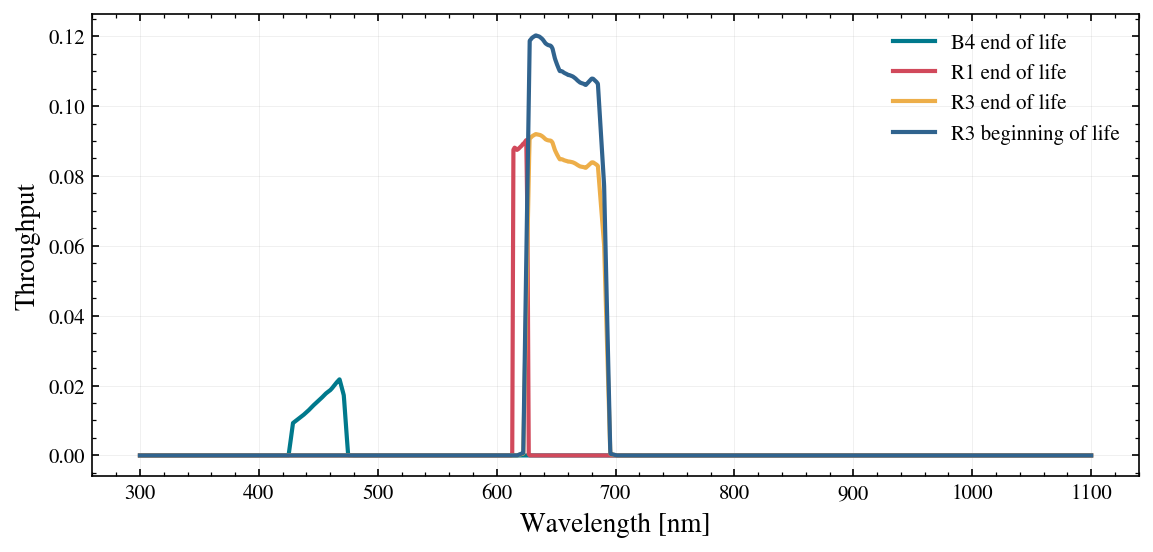

In [5]:
names = ["B1", "B2", "B3", "B4", "B5", "B6", "R1", "R2", "R3", "R4", "R5", "R6"]
rows = []
print(f"{'filter':7s} {'designation':12s} {'lambda [nm]':>11s} {'S/N in 1 h':>10s}")
for name in names:
    s = Simulation.from_default(filter=name, hoststarmag=4.83, hoststar_band="johnson_v", planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)
    desig = [k for k, v in FILTERS.items() if v == FILTERS[name] and k != name][0]
    rows.append((name, desig, s.telescope.primary_filter.to_value(u.nm), s.get_snr(3600, 100)["snr"]))
    print(f"{name:7s} {desig:12s} {rows[-1][2]:11.0f} {rows[-1][3]:10.2f}")

fig, ax = plt.subplots(figsize=(9, 4))
for name in ("B4", "R1", "R3"):
    Simulation.from_default(filter=name).plot_bandpass(ax=ax, label=f"{name} end of life")
Simulation.from_default(filter="R3", lifetime="bol").plot_bandpass(ax=ax, label="R3 beginning of life")
ax.legend()
plt.show()

The wide filters (B4 = F450W, R3 = F659W) collect several times the planet photons of the narrow
ones (N = narrow, W = wide), so for a detection they win outright; the narrow filters are for
colours and for the methane band at 725 nm (R5).

***
## 5. The photometric aperture

The planet is measured in one resolution element (`aperture="resel"`): a circle of area
$\pi(\lambda/2D)^2$ that holds about 46 % of the encircled energy at 20 pixels of the 8.7 mas
pixel scale. The same resel also collects the zodi and exozodi.

aperture: resel, 21.4 pix, solid angle 0.00161 arcsec2, encircled energy 0.456, peak-pixel fraction 0.063


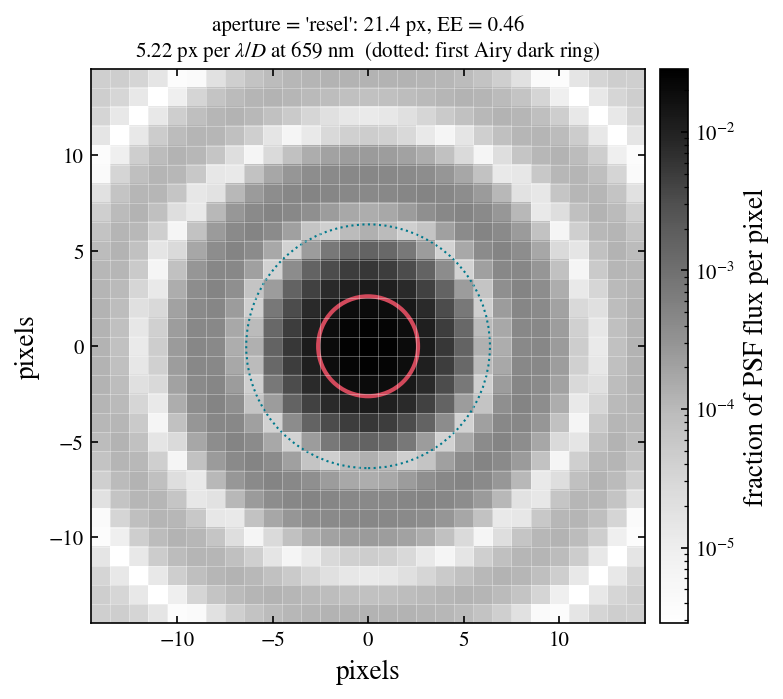

In [6]:
s = sim.sensor
print(f"aperture: {s.aperture}, {s.num_psf_pixels:.1f}, solid angle {s.aperture_solid_angle:.5f}, encircled energy {s.ee_fraction:.3f}, peak-pixel fraction {s.peak_pixel_fraction:.3f}")
fig, ax = sim.plot_aperture()
plt.show()

***
## Summary

```python
Telescope.from_default(filter="R3"); Sensor.from_default(tel, ...); get_scene(tel, ...); Coronagraph.from_default(tel, ...)
Simulation.from_components(tel, sen, scene, cor)
sim.update(scene__star__mag=6, coronagraph__ppgain=100, coronagraph__separation=0.15); sim.reset()
Simulation.from_default(filter="B4", lifetime="bol")      # FILTERS has the twelve names
```

Next: [03 — contrast, post-processing gain and separation](03_contrast_gain_separation.ipynb).